# B6 — Cost-sensitive evaluation

Cost ratio C_FN/C_FP swept over {10, 50, 100, 500}; thresholds chosen on validation year 2022 (KEV as of 2023-01-01), never on test. Calibration first. Needs B2 run first. Code: `src/models/b6_cost.py`.

In [1]:
import os
import sys
from pathlib import Path

# Every src/ path is relative to the project root (data/..., outputs/...).
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
import warnings; warnings.filterwarnings("ignore")  # spurious macOS Accelerate matmul warnings in SVD
import pandas as pd
pd.set_option("display.width", 200)

from src.models.b6_cost import run

In [2]:
out = run()
out["calibration"].mean().round(5)

seed         4.50000
brier        0.00137
ece          0.00035
mean_prob    0.00110
base_rate    0.00136
dtype: float64

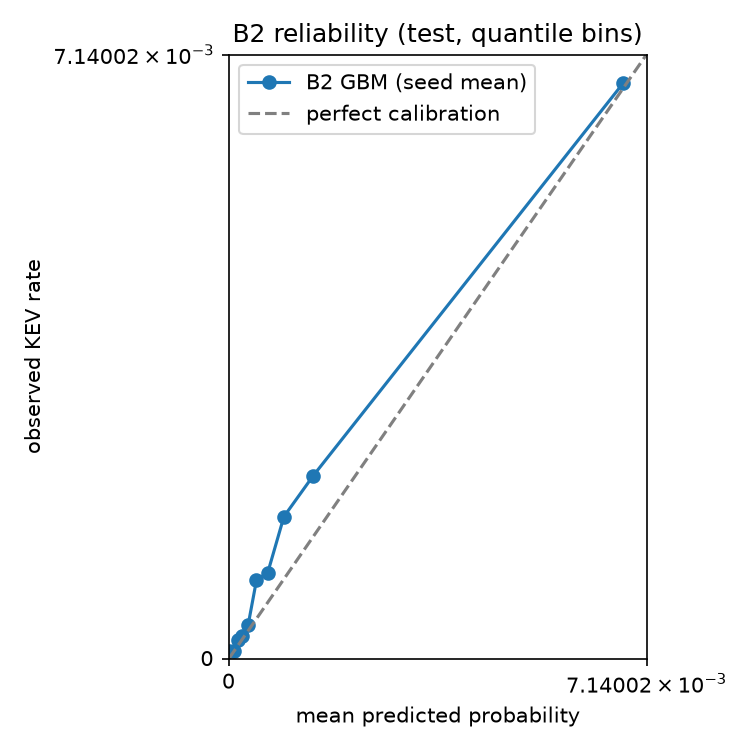

In [3]:
from IPython.display import Image
Image("outputs/b6_reliability.png")

In [4]:
out["summary"]

,ratio,policy,cost_mean,cost_std,n_remediated_mean,n_remediated_std,kev_caught_mean,kev_caught_std
11,10,remediate_none,13.64,NaN,0.0,NaN,0.0,NaN
9,10,gbm_validated_threshold,13.65,0.22,84.8,59.69,7.6,2.99
5,10,gbm_bayes_threshold_ref,13.68,0.15,103.0,21.23,8.7,1.77
7,10,gbm_budget_10_per_month,14.54,0.10,470.0,0.00,24.2,2.04
3,10,cvss_v3_budget_10_per_month,15.18,0.11,470.0,0.00,11.2,2.25
8,10,gbm_budget_50_per_month,21.41,0.17,2350.0,0.00,53.7,3.59
4,10,cvss_v3_budget_50_per_month,22.40,0.11,2350.0,0.00,33.3,2.26
6,10,gbm_budget_100_per_month,30.79,0.17,4700.0,0.00,74.2,3.58
2,10,cvss_v3_budget_100_per_month,31.99,0.13,4700.0,0.00,49.6,2.67
1,10,cvss_ge_9,101.62,NaN,21387.0,NaN,133.0,NaN


In [5]:
out["best"]

,policy,cost_mean
ratio,,
10,remediate_none,13.64
50,gbm_budget_10_per_month,64.85
100,gbm_budget_50_per_month,122.87
500,gbm_bayes_threshold_ref,468.88


## Threshold stability across seeds (validation year has few KEV)

In [6]:
out["thresholds"].groupby("ratio").threshold.describe()

,count,mean,std,min,25%,50%,75%,max
ratio,,,,,,,,
10,10.0,0.113892,0.035072,0.063474,0.093931,0.112381,0.135282,0.169652
50,10.0,0.036405,0.022890,0.009927,0.018288,0.032234,0.050607,0.071862
100,10.0,0.014816,0.009498,0.005897,0.009703,0.012159,0.015527,0.039108
500,10.0,0.000303,0.000098,0.000188,0.000257,0.000276,0.000331,0.000534
